# Common spatial patterns

In [1]:
import matplotlib.pyplot as plt
import mne
from mne.decoding import CSP
from moabb.datasets import BNCI2014_001
import numpy as np
import os
from scipy.linalg import eigh
from scipy.signal import periodogram, hilbert
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import StratifiedKFold, cross_val_score

np.random.seed(42)
mne.set_log_level('WARNING')


## Exercise 1: Load the data

The following uses [MOABB](https://moabb.neurotechx.com/docs/index.html) to download the [BNCI2014_001 dataset](https://moabb.neurotechx.com/docs/generated/moabb.datasets.BNCI2014_001.html) from [Tangermann et al. 2012](https://www.frontiersin.org/journals/neuroscience/articles/10.3389/fnins.2012.00055/full). The dataset contains motor imagery data with 4 classes: left hand, right hand, feet, and tongue. We will limit the data to the hands only.
1. Read the dataset documentation to get to know the data properties and the task underlying the data.

C:\Users\thano\anaconda3\envs\bci-BKI323\Lib\site-packages\moabb\datasets\download.py:97: RuntimeWarning: Setting non-standard config type: "MNE_DATASETS_BNCI_PATH"
  set_config(key, get_config("MNE_DATA"))
C:\Users\thano\anaconda3\envs\bci-BKI323\Lib\site-packages\urllib3\connectionpool.py:1063: InsecureRequestWarning: Unverified HTTPS request is being made to host 'lampx.tugraz.at'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/1.26.x/advanced-usage.html#ssl-warnings
  warnings.warn(
100%|#####################################| 44.1M/44.1M [00:00<00:00, 20.9GB/s]
SHA256 hash of downloaded file: 7e731ee8b681d5da6ecb11ae1d4e64b1653c7f15aad5d6b7620b25ce53141e80
Use this value as the 'known_hash' argument of 'pooch.retrieve' to ensure that the file hasn't changed if it is downloaded again in the future.
C:\Users\thano\anaconda3\envs\bci-BKI323\Lib\site-packages\urllib3\connectionpool.py:1063: InsecureRequestWarning: Unverified HTTPS request is

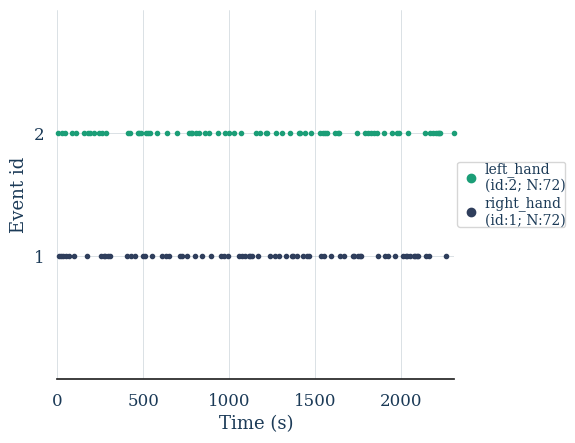

In [2]:
# Subject to analyze
i_subject = 3

# Load dataset
dataset = BNCI2014_001()
data = dataset.get_data(subjects=[i_subject])
raw = mne.concatenate_raws([r.copy() for r in data[i_subject]["1test"].values()])

# Extract events
events, event_id = mne.events_from_annotations(raw, event_id={"right_hand": 1, "left_hand": 2})

# Visualize event timeline
mne.viz.plot_events(events=events, event_id=event_id, sfreq=raw.info["sfreq"])

# Slice to epochs/trials
epo = mne.Epochs(raw, events, event_id, tmin=0.5, tmax=3.5, baseline=None, preload=True, picks="eeg", reject={"eeg":140e-6})


## Exercise 2: Fitting CSP
The most crucial prerequisite for CSP is that it is only suitable for narrowband-filtered data. But for our dataset, we do not yet know which band would be the best for the final classification performance. A first indication can be gained by visually inspecting the PSDs for the two classes separately. 

1. Look at the PSD plot. Given the PSD, which frequency bands would you have a look at?
1. Apply a bandpass filter (`mne.filter()`) to limit the frequency content to that specific band.
1. Use `epo.get_data()` to extract the data and `epo.events[:, 2] - 1` to extract the labels.
1. Fit a CSP model using MNE's `CSP()`. Set the `n_components` to 4 and the `component_order` to 'alternate'.
1. Use `mne.viz.plot_topomap()` to plot the spatial patterns stored as an attribute in your `CSP` as `patterns_`. 
1. Try out a few frequency bands and plot the resulting patterns. Which band seems to work best?

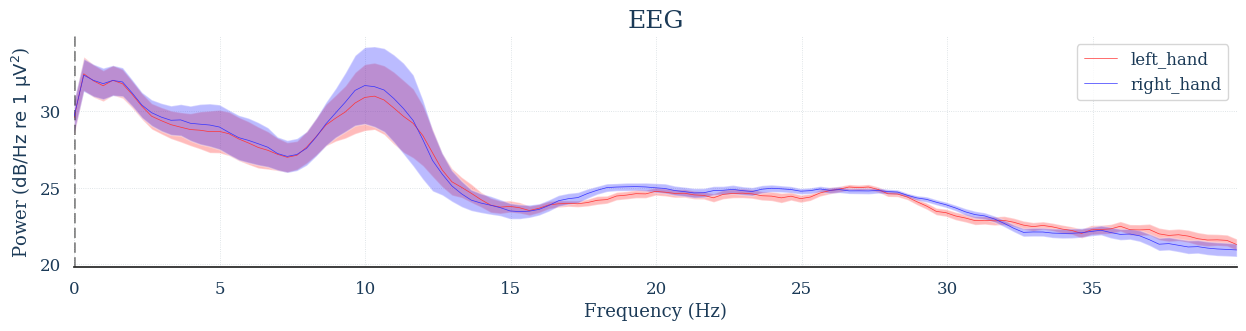

In [3]:
# Spectrum
fig, ax = plt.subplots(1, 1, figsize=(15, 3))
for i, (label, clr) in enumerate(zip(['left_hand', 'right_hand'], ['#ff3333', '#3333ff'])):
    epo[label].plot_psd(ax=ax, show=False, average=True, spatial_colors=False, color=clr, fmax=40)
    ax.get_lines()[-1].set_label(label)
ax.legend()

EEG shape: (142, 22, 751)
Labels shape: (142,)
Class counts: (array([0, 1]), array([72, 70]))


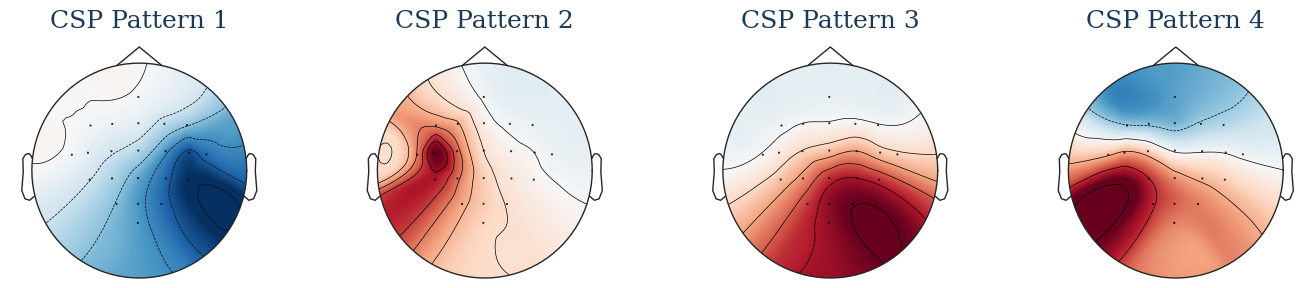

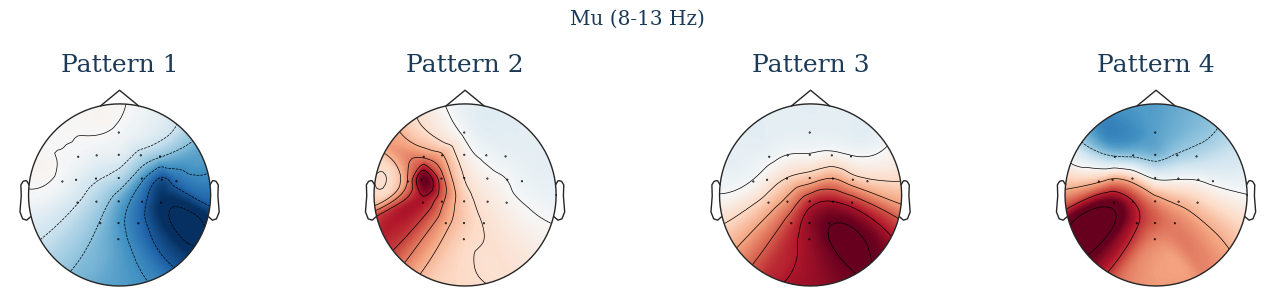

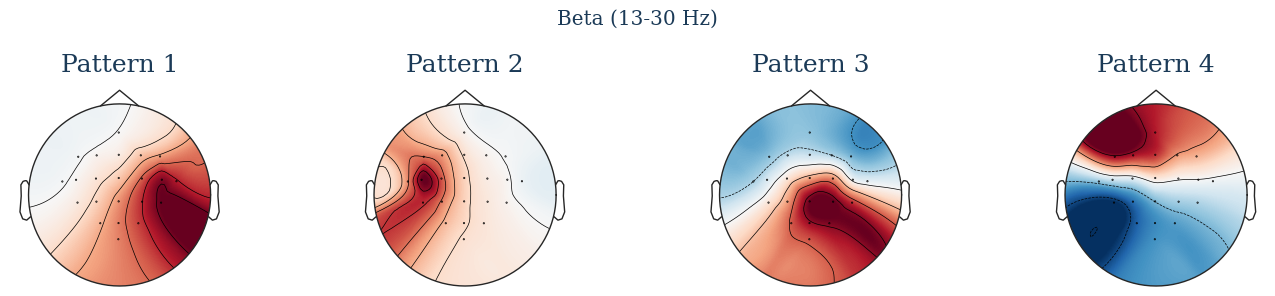

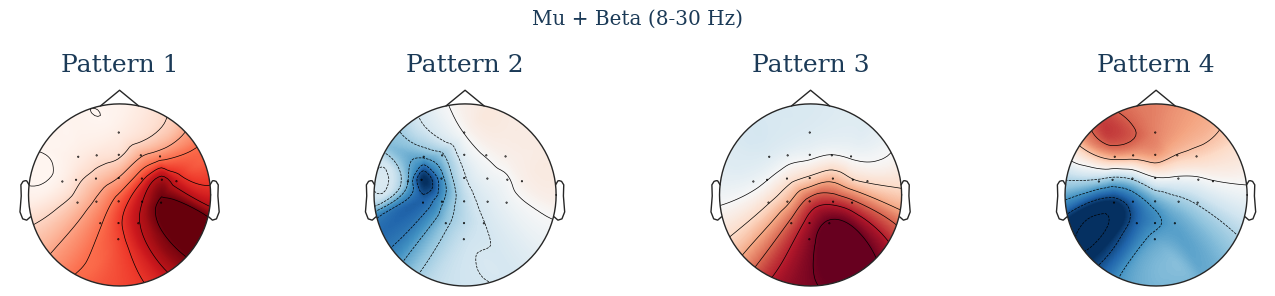

In [ ]:
# Answer here

# 1. Select the frequency band
l_freq = 8
h_freq = 13

# 2. Filter a copy of the epochs
epo_filtered = epo.copy().filter(l_freq, h_freq)

# 3. Extract EEG and labels
X = epo_filtered.get_data()
y = epo_filtered.events[:, 2] - 1

print("EEG shape:", X.shape)
print("Labels shape:", y.shape)
print("Class counts:", np.unique(y, return_counts=True))

# 4. Fit CSP
csp = CSP( n_components=4,component_order="alternate")
csp.fit(X, y)

# 5. Plot the first four spatial patterns
fig, axes = plt.subplots(1, 4, figsize=(14, 3))

for i in range(4):
    mne.viz.plot_topomap(
        csp.patterns_[i, :],
        epo_filtered.info,
        axes=axes[i],
        show=False
    )
    axes[i].set_title(f"CSP Pattern {i+1}")

plt.tight_layout()
plt.show()

bands = {  "Mu (8-13 Hz)": (8, 13), "Beta (13-30 Hz)": (13, 30), "Mu + Beta (8-30 Hz)": (8, 30),}

for band_name, (low, high) in bands.items():

    # Filter EEG
    epo_band = epo.copy().filter(low, high)

    # Extract EEG data and labels
    X = epo_band.get_data()
    y = epo_band.events[:, 2] - 1

    # Fit a new CSP for this band
    csp = CSP(
        n_components=4,
        component_order="alternate"
    )
    csp.fit(X, y)

    # Plot four spatial patterns
    fig, axes = plt.subplots(1, 4, figsize=(14, 3))

    for i in range(4):
        mne.viz.plot_topomap(
            csp.patterns_[i, :],
            epo_band.info,
            axes=axes[i],
            show=False
        )
        axes[i].set_title(f"Pattern {i+1}")

    fig.suptitle(band_name)
    plt.tight_layout()
    plt.show()

#6 The band from 8-13 Hz seems to work best, as it gives filtered signals that are clearly coming from the right hemisphere for class 1 and the left hemisphere for class 2.
# The other frequency bands show the same, but for filter 3 and 4 we also see a bit more of the filtered signal
# showing up in the frontal area's, which indicates an artifact of blinking making its way into the signal.

## Exercise 3: Binary classification using CSP and LDA

1. Build a classifier using sklearn's `Pipeline`, a `CSP()` and an `LDA()`. In the CSP, now also set `log=True` because we use an LDA.
1. Use sklearn's `cross_val_score()` to evaluate the pipeline of the data. Print the accuracy.

In [9]:
# Answer here

# Prepare the EEG
epo_filtered = epo.copy().filter(8, 13)

X = epo_filtered.get_data()
y = epo_filtered.events[:, 2] - 1

# Create the CSP + LDA pipeline
pipeline = Pipeline([
    ("csp", CSP(
        n_components=4,
        component_order="alternate",
        log=True
    )),
    ("lda", LDA())
])

# Create 5 stratified folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the full pipeline
scores = cross_val_score(
    pipeline,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Accuracy for each fold:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

for band_name, (low, high) in bands.items():
    epo_band = epo.copy().filter(low, high)
    X_band = epo_band.get_data()
    y_band = epo_band.events[:, 2] - 1

    scores = cross_val_score(
        pipeline, X_band, y_band,
        cv=cv, scoring="accuracy"
    )

    print(band_name, ":", round(scores.mean(), 3))



Accuracy for each fold: [1.         0.96551724 1.         1.         1.        ]
Mean accuracy: 0.993103448275862
Standard deviation: 0.013793103448275846
Mu (8-13 Hz) : 0.993
Beta (13-30 Hz) : 0.951
Mu + Beta (8-30 Hz) : 0.979


## Exercise 4: Implement your own CSP

1. Build your own `fit_csp(X, y)` function that takes data `X` and labels `y` and returns the eigenvalues and eigenvectors (CSP filters) using only `numpy` functionality. Make sure that the eigenvectors are sorted on alternating eigenvalues (highest, lowest, second highest, second lowest, etc.). The CSP is computed as the generalized eigenvalue decomposition of $\Sigma_1$ and $\Sigma_2$, for which you can use scipy's `eigh()`.
1. Compare your CSP filters with those from `mne.CSP(component_order='alternate')` by visualizing its attribute `filters_` using `mne.viz.plot_topomap`.
1. The filters should be similar. What do you observe?

My filters: (22, 22)
MNE filters: (22, 22)


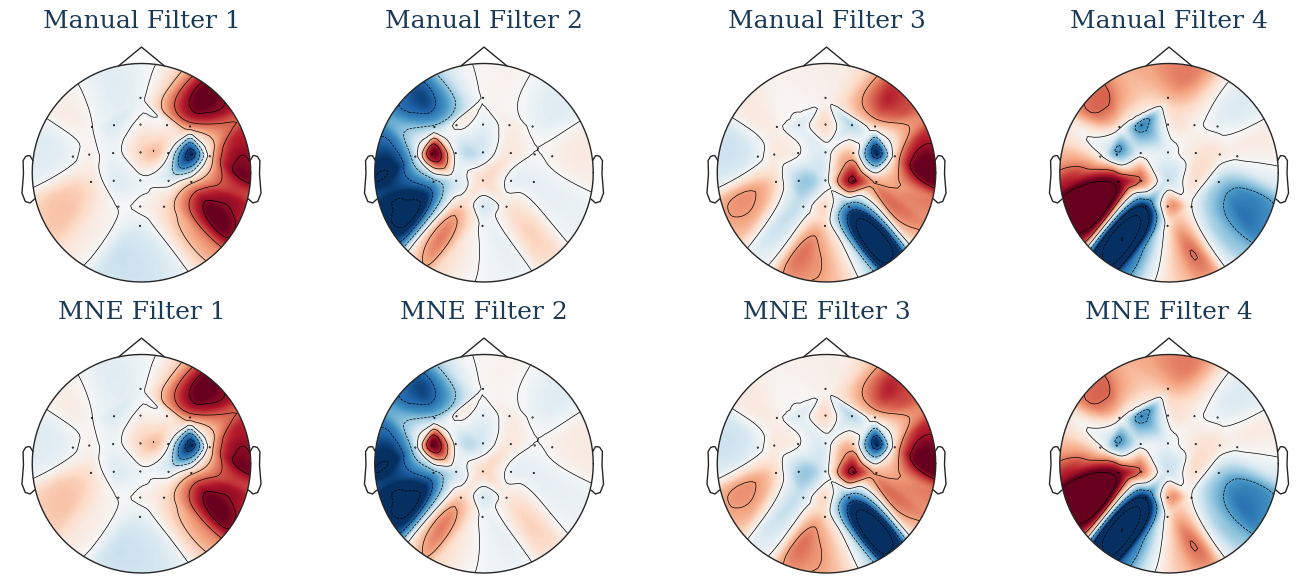

In [11]:
# Answer

def fit_csp(X, y):
    n_channels = X.shape[1]
    classes = np.unique(y)

    covariances = []

    # Step 1: Estimate covariance for each class
    for cls in classes:
        X_class = X[y == cls]

        # (epochs, channels, time)
        # (channels, all class time samples)
        X_concat = X_class.transpose(1, 0, 2).reshape(n_channels, -1)

        cov = np.cov(X_concat, bias=True)
        covariances.append(cov)

    cov_0, cov_1 = covariances

    # Step 2: Composite covariance
    cov_total = cov_0 + cov_1

    # Step 3: Generalized eigenvalue decomposition
    eigenvalues, eigenvectors = eigh(cov_0, cov_total)

    # Step 4: Alternate largest and smallest eigenvalues
    sorted_idx = np.argsort(eigenvalues)
    alternate_idx = np.empty_like(sorted_idx)

    middle = len(sorted_idx) // 2

    alternate_idx[0::2] = sorted_idx[middle:][::-1]
    alternate_idx[1::2] = sorted_idx[:middle]

    eigenvalues = eigenvalues[alternate_idx]
    eigenvectors = eigenvectors[:, alternate_idx]

    return eigenvalues, eigenvectors



# Use the same filtered data as before
X = epo_filtered.get_data()
y = epo_filtered.events[:, 2] - 1


eigenvalues, eigenvectors = fit_csp(X, y)

# Eigenvectors are columns, filters should be rows
manual_filters = eigenvectors.T

# MNE implementation
mne_csp = CSP(
    n_components=4,
    component_order="alternate"
)
mne_csp.fit(X, y)

print("My filters:", manual_filters.shape)
print("MNE filters:", mne_csp.filters_.shape)

fig, axes = plt.subplots(2, 4, figsize=(14, 6))

for i in range(4):
    ours = manual_filters[i].copy()
    theirs = mne_csp.filters_[i].copy()

    # Normalize for visual comparison
    ours /= np.linalg.norm(ours)
    theirs /= np.linalg.norm(theirs)

    # Align signs (eigenvector signs are arbitrary)
    if np.dot(ours, theirs) < 0:
        ours *= -1

    vmax = max(np.max(np.abs(ours)),
               np.max(np.abs(theirs)))

    mne.viz.plot_topomap(
        ours, epo_filtered.info,
        axes=axes[0, i],
        vlim=(-vmax, vmax),
        show=False
    )

    mne.viz.plot_topomap(
        theirs, epo_filtered.info,
        axes=axes[1, i],
        vlim=(-vmax, vmax),
        show=False
    )

    axes[0, i].set_title(f"Manual Filter {i+1}")
    axes[1, i].set_title(f"MNE Filter {i+1}")

plt.tight_layout()
plt.show()



## Exercise 5: Order of labels
CSP solves a generalized eigenvalue decomposition. This means that the following two objectives give the same filters, just in reversed order:
$$\arg\max_\mathbf{w}\frac{\mathbf{w}^\top\Sigma_1\mathbf{w}}{\mathbf{w}^\top\Sigma_2\mathbf{w}}, 
\arg\max_\mathbf{w}\frac{\mathbf{w}^\top\Sigma_2\mathbf{w}}{\mathbf{w}^\top\Sigma_1\mathbf{w}}
$$
1. Verify this by swapping the labels and comparing the CSP eigenvalue spectrum and filters.
2. Additionally, verify this by computing the decoding accuracy for each component and comparing with and without swapping labels.


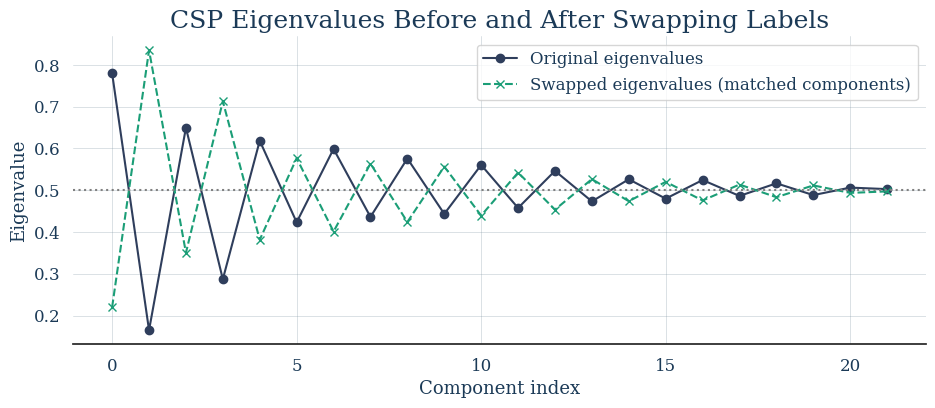

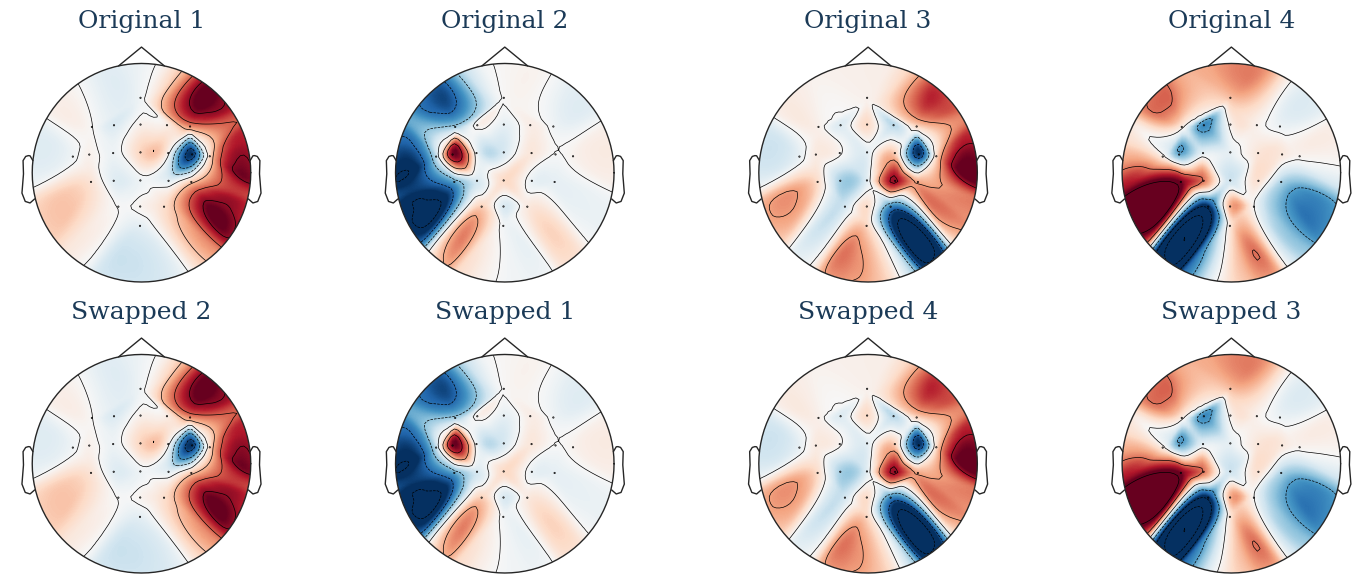

Component 1: Original = 0.797, Swapped = 0.797
Component 2: Original = 0.874, Swapped = 0.874
Component 3: Original = 0.705, Swapped = 0.705
Component 4: Original = 0.818, Swapped = 0.818


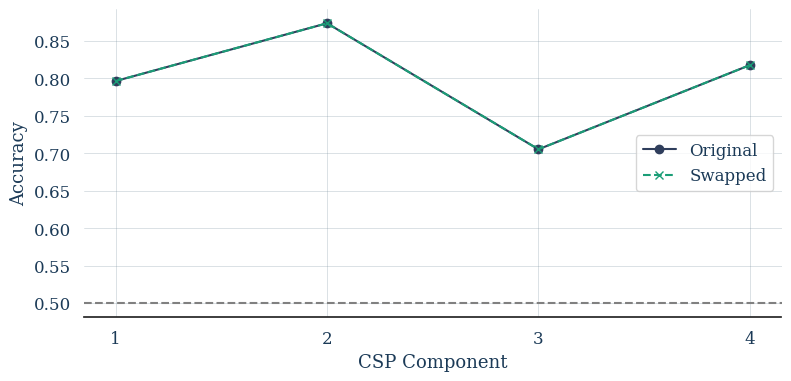

In [14]:
# Answer here

# Use the same 8-13 Hz data as before
epo_filtered = epo.copy().filter(8, 13)

X = epo_filtered.get_data()
y = epo_filtered.events[:, 2] - 1

# Swap class labels: 0 to 1 and 1 to 0
y_swapped = 1 - y

# Fit our CSP with original and swapped labels
eig_original, vec_original = fit_csp(X, y)
eig_swapped, vec_swapped = fit_csp(X, y_swapped)

# Match corresponding components under alternate ordering
# Component 1 <-> 2, component 3 <-> 4, etc.
pair_idx = np.arange(len(eig_original)).reshape(-1, 2)[:, ::-1].ravel()

# Compare eigenvalues
plt.figure(figsize=(11, 4))

plt.plot(eig_original, "o-", label="Original eigenvalues")
plt.plot(eig_swapped[pair_idx], "x--",
         label="Swapped eigenvalues (matched components)")

plt.axhline(0.5, color="gray", linestyle=":")
plt.xlabel("Component index")
plt.ylabel("Eigenvalue")
plt.title("CSP Eigenvalues Before and After Swapping Labels")
plt.legend()
plt.show()


fig, axes = plt.subplots(2, 4, figsize=(15, 6))

for i in range(4):

    original_filter = vec_original[:, i].copy()
    swapped_filter = vec_swapped[:, pair_idx[i]].copy()

    # Normalize both filters
    original_filter /= np.linalg.norm(original_filter)
    swapped_filter /= np.linalg.norm(swapped_filter)

    # Correct arbitrary eigenvector sign differences
    if np.dot(original_filter, swapped_filter) < 0:
        swapped_filter *= -1

    vmax = max(
        np.max(np.abs(original_filter)),
        np.max(np.abs(swapped_filter))
    )

    mne.viz.plot_topomap(
        original_filter,
        epo_filtered.info,
        axes=axes[0, i],
        vlim=(-vmax, vmax),
        show=False
    )

    mne.viz.plot_topomap(
        swapped_filter,
        epo_filtered.info,
        axes=axes[1, i],
        vlim=(-vmax, vmax),
        show=False
    )

    axes[0, i].set_title(f"Original {i+1}")
    axes[1, i].set_title(f"Swapped {pair_idx[i]+1}")

plt.tight_layout()
plt.show()


# Use the filtered EEG data
X = epo.copy().filter(8, 13).get_data()
y = epo.events[:, 2] - 1

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = np.zeros((2, 4, 5))

# Original labels and swapped labels
for swap in range(2):
    labels = y if swap == 0 else 1 - y

    for fold, (train, test) in enumerate(cv.split(X, y)):

        csp = CSP(n_components=4, component_order="alternate", log=True)

        X_train = csp.fit_transform(X[train], labels[train])
        X_test = csp.transform(X[test])

        # Evaluate each CSP component separately
        for i in range(4):
            lda = LDA()
            lda.fit(X_train[:, [i]], labels[train])
            scores[swap, i, fold] = lda.score(
                X_test[:, [i]], labels[test]
            )

# Compare corresponding components
original = scores[0].mean(axis=1)
swapped = scores[1].mean(axis=1)

for i in range(4):
    print(f"Component {i+1}: Original = {original[i]:.3f}, "
          f"Swapped = {swapped[i ^ 1]:.3f}")

# Plot
plt.figure(figsize=(9, 4))
plt.plot(range(1, 5), original, "o-", label="Original")
plt.plot(range(1, 5), swapped[[1, 0, 3, 2]], "x--", label="Swapped")
plt.axhline(0.5, color="gray", linestyle="--")
plt.xticks(range(1, 5))
plt.xlabel("CSP Component")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
